In [1]:
# Cell 1: Import libraries for data manipulation and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style for the plots to make them look professional for your report
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Cell 2: Load the raw dataset
# Ensure "Palo Alto Networks.csv" is in the same folder as your Jupyter Notebook
df = pd.read_csv("Palo Alto Networks.csv")

# Display the first 5 rows to verify it loaded correctly
display(df.head())

# Check the data types and look for any missing values across the 35 columns
print("\nDataset Info:")
df.info()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   int64 
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EnvironmentSatisfaction   1470 non-null   int64 
 9   Gender                    1470 non-null   object
 10  HourlyRate                1470 non-null   int64 
 11  JobInvolvement            1470 non-null   int64 
 12  JobLevel                  1470 non-null   int64 
 13  JobRole                   1470 non-null   object
 14  JobSatisf

In [3]:
# Cell 3: Validate ordinal scales (1-4) and handle missing values
# We are focusing on the survey/satisfaction metrics vital for our indices
satisfaction_cols = [
    'JobInvolvement', 
    'JobSatisfaction', 
    'EnvironmentSatisfaction', 
    'RelationshipSatisfaction', 
    'WorkLifeBalance'
]

# Convert columns to numeric, coercing any errors to NaN (Not a Number)
for col in satisfaction_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    
    # Fill any missing values with the median of that specific column 
    # (Median is better than mean for 1-4 ordinal scales to keep whole numbers)
    df[col].fillna(df[col].median(), inplace=True)

print("Data validation complete. Missing satisfaction values handled.")

Data validation complete. Missing satisfaction values handled.


C:\Users\mukul\AppData\Local\Temp\ipykernel_17348\2716780031.py:17: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)
C:\Users\mukul\AppData\Local\Temp\ipykernel_17348\2716780031.py:17: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For exa

In [4]:
# Cell 4: Create the composite Engagement Index
# This averages out the four key satisfaction metrics to create a unified score out of 4.0
df['Engagement_Index'] = df[['JobInvolvement', 
                             'JobSatisfaction', 
                             'EnvironmentSatisfaction', 
                             'RelationshipSatisfaction']].mean(axis=1)

# Display a statistical summary of the new index to include in your research paper
print("Engagement Index Summary Statistics:")
display(df['Engagement_Index'].describe())

Engagement Index Summary Statistics:


count    1470.000000
mean        2.723129
std         0.504026
min         1.250000
25%         2.500000
50%         2.750000
75%         3.000000
max         4.000000
Name: Engagement_Index, dtype: float64

In [5]:
# Cell 5: Build the Burnout Risk Indicator
# The logic: Overtime combined with poor Work-Life Balance (score of 1 or 2) leads to burnout.

def assign_burnout_risk(row):
    # Check if employee works overtime
    overtime = row['OverTime'] == 'Yes'
    # Check if work-life balance is poor or fair (1 or 2 out of 4)
    low_wlb = row['WorkLifeBalance'] <= 2
    
    # Assign risk tiers
    if overtime and low_wlb:
        return 'High'
    elif overtime or low_wlb:
        return 'Medium'
    else:
        return 'Low'

# Apply the function row-by-row to create the new column
df['Burnout_Risk'] = df.apply(assign_burnout_risk, axis=1)

# Check the distribution of the new risk categories
print("Burnout Risk Distribution:")
print(df['Burnout_Risk'].value_counts())

Burnout Risk Distribution:
Burnout_Risk
Low       756
Medium    588
High      126
Name: count, dtype: int64


In [6]:
# Cell 6: Build the Workload Stress Indicator
# This metric quantifies physical and mental toll based on travel and extra hours.

def calculate_stress_indicator(row):
    stress_score = 0
    
    # Add points for overtime
    if row['OverTime'] == 'Yes':
        stress_score += 2
        
    # Add points for business travel frequency
    if row['BusinessTravel'] == 'Travel_Frequently':
        stress_score += 2
    elif row['BusinessTravel'] == 'Travel_Rarely':
        stress_score += 1
        
    return stress_score # Final score ranges from 0 (lowest stress) to 4 (highest stress)

# Apply the function to the dataset
df['Workload_Stress_Indicator'] = df.apply(calculate_stress_indicator, axis=1)

print("Workload Stress Indicator created successfully.")

Workload Stress Indicator created successfully.


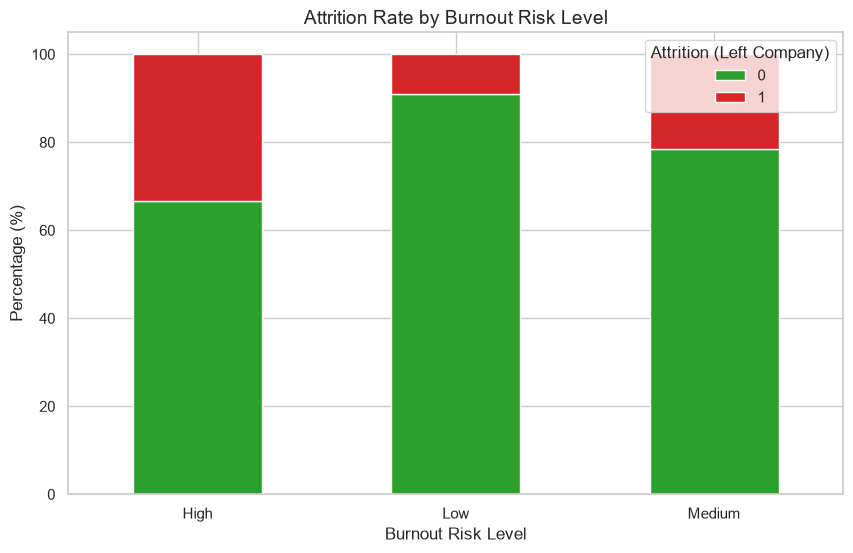

In [7]:
# Cell 7: Analyze how Burnout Risk correlates with actual Attrition
# This proves to HR that your Burnout metric is a valid early-warning sign.

# Calculate the percentage of attrition within each burnout risk category
burnout_attrition = df.groupby('Burnout_Risk')['Attrition'].value_counts(normalize=True).unstack() * 100

# Plot the results
ax = burnout_attrition.plot(kind='bar', stacked=True, color=['#2ca02c', '#d62728'])
plt.title('Attrition Rate by Burnout Risk Level', fontsize=14)
plt.xlabel('Burnout Risk Level', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.legend(title='Attrition (Left Company)')
plt.xticks(rotation=0)

# Add this chart to your research paper
plt.show()

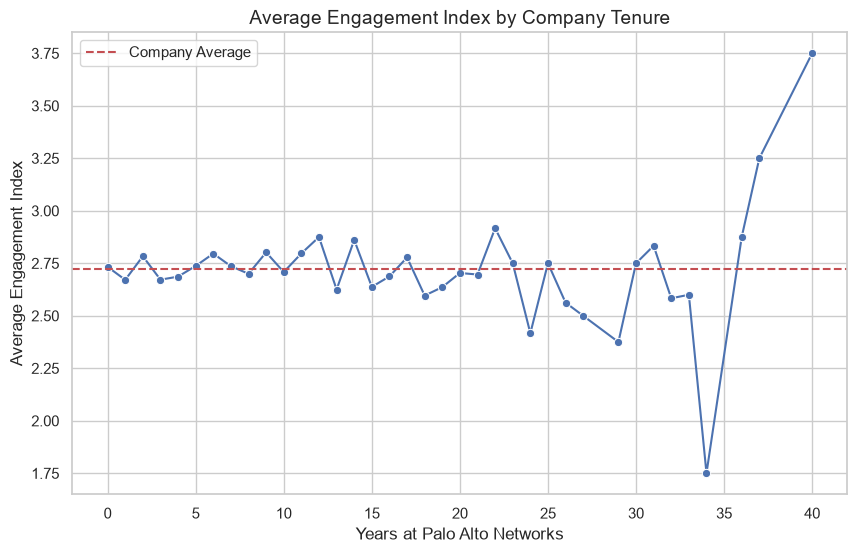

In [8]:
# Cell 8: Analyze engagement stagnation by tenure
# Are employees disengaging after a certain number of years?

# Group by YearsAtCompany and calculate average engagement
tenure_engagement = df.groupby('YearsAtCompany')['Engagement_Index'].mean().reset_index()

# Plot a line chart to show the trend
sns.lineplot(data=tenure_engagement, x='YearsAtCompany', y='Engagement_Index', marker='o', color='b')
plt.title('Average Engagement Index by Company Tenure', fontsize=14)
plt.xlabel('Years at Palo Alto Networks', fontsize=12)
plt.ylabel('Average Engagement Index', fontsize=12)
plt.axhline(y=df['Engagement_Index'].mean(), color='r', linestyle='--', label='Company Average')
plt.legend()

# Highlight dips in engagement (e.g., between years 3-5) in your research paper
plt.show()

In [9]:
# Cell 9: Save the cleaned and feature-engineered dataset
# This file will be used as the data source for your Streamlit dashboard application.

export_filename = "Palo_Alto_Processed.csv"
df.to_csv(export_filename, index=False)

print(f"Data processing and EDA complete. File saved successfully as: {export_filename}")
print("You are now ready to build the Streamlit dashboard using this file.")

Data processing and EDA complete. File saved successfully as: Palo_Alto_Processed.csv
You are now ready to build the Streamlit dashboard using this file.
